# Individuals dated by one source only
Three groups of individuals who can be placed in time by a single kind of date:

1. **Floruit only**: a floruit (Wikidata P1317, or "fl." in the description) precise to the year or decade, and no birth date, no death date and no work date, at any precision. They are placed by their floruit.
2. **Work inception only**: at least one work with an inception date, and no birth date, no death date and no floruit, at any precision. They may also have publication dates. They are placed by the median of their inception years.
3. **Century or millennium only**: at least one date (birth, death, floruit, "fl.", work inception or publication), but none precise to the year or decade. They are placed by the first date available, in that order.

Same floruit methods as notebooks 03 and 04_a. Wikidata values only, before enrichment.

In [1]:
import duckdb
import matplotlib.pyplot as plt
import polars as pl

from style import *

DB_PATH = '../data/cultura/humans_clean_non_enriched_v3.duckdb'

PRECISE = ['day', 'month', 'year', 'decade']
MID_DECADE = 5
FIRST_CENTURY = -1000
LAST_CENTURY = 2000
GROUPS = {'Floruit only': BLUE, 'Work inception only': ORANGE, 'Century or millennium only': GREEN}

pl.Config.set_tbl_rows(40)
apply_style()

connection = duckdb.connect(DB_PATH, read_only=True)
database_size = connection.execute('SELECT count(*) FROM individual').fetchone()[0]
print(f'{database_size:,} individuals in the database')

13,002,897 individuals in the database


## Load the data
### 1. Birth, death, floruit property and work dates

In [2]:
dates = connection.execute('''
    WITH work_dates AS (
        SELECT individual_work.qid,
               bool_or(work.inception.year IS NOT NULL) AS has_inception,
               bool_or(work.publication_date.year IS NOT NULL) AS has_publication,
               round(median(CASE WHEN work.inception.precision = 'decade' THEN work.inception.year + 5
                                  WHEN work.inception.precision IN ('century', 'millennium') AND work.inception.year > 0 THEN work.inception.year - 1
                                  ELSE work.inception.year END))::BIGINT AS inception_year
        FROM individual_work
        JOIN work ON work.entity.qid = individual_work.work_qid
        GROUP BY individual_work.qid
    )
    SELECT individual.entity.qid AS qid,
           len(individual.birth_date) > 0 AS has_birth,
           len(individual.death_date) > 0 AS has_death,
           len(individual.floruit_date) > 0 AS has_floruit_property,
           coalesce(work_dates.has_inception, FALSE) AS has_inception,
           coalesce(work_dates.has_publication, FALSE) AS has_publication,
           work_dates.inception_year
    FROM individual
    LEFT JOIN work_dates ON work_dates.qid = individual.entity.qid
''').pl()
assert dates.height == database_size
dates.select(pl.exclude('qid', 'inception_year').sum())

has_birth,has_death,has_floruit_property,has_inception,has_publication
u32,u32,u32,u32,u32
7487896,3531434,68641,143046,2666331


### 2. Wikidata floruit (P1317)
The earliest floruit precise to the year or decade.

In [3]:
floruit_property = connection.execute('''
    SELECT entity.qid AS qid,
           list_min([CASE WHEN date.precision = 'decade' THEN date.year + 5 ELSE date.year END
                     FOR date IN floruit_date IF date.precision IN ('day', 'month', 'year', 'decade')]) AS year
    FROM individual
    WHERE len(floruit_date) > 0
''').pl().drop_nulls('year')
print(f'{floruit_property.height:,} individuals with a precise floruit')

55,835 individuals with a precise floruit


### 3. "fl." in the description, with one or two dates
Same parsing as notebooks 03 and 04.

In [4]:
fl_pattern = r'\bfl\.\s*(?:c\.|ca\.|circa|about|in the|around)?\s*(\d{1,4})(s?)\b(?:[^,;)]*?\b(B\.?\s?C\.?(?:\s?E\.?)?))?'
range_pattern = r'\bfl\.[^,;)]*?\d\s*(?:s|st|nd|rd|th|\.)?\s*(?:-|–|—|/|\bto\b|\band\b)\s*(?:c\.\s*)?\d'
century_pattern = r'\bfl\.[^,;)]*?\b(\d{1,2})(?:st|nd|rd|th|\.)?\s*(?:-\s*\d{1,2}(?:st|nd|rd|th|\.)?\s*)?(century|centuries|millennium)(?:[^,;)]*?\b(B\.?\s?C\.?(?:\s?E\.?)?))?'

fl_text = (
    connection.execute('''
        SELECT entity.qid AS qid, entity.description AS description
        FROM individual
        WHERE regexp_matches(entity.description, '\\bfl\\.')
    ''').pl()
    .with_columns(
        pl.col('description').str.extract_groups(fl_pattern).alias('match'),
        pl.col('description').str.extract_groups(century_pattern).alias('century_match'),
        pl.col('description').str.contains(r'\bfl\.\s*\d{1,2}\.').alias('is_ordinal_century'),
    )
    .with_columns(
        pl.col('match').struct.field('1').cast(pl.Int64).alias('year'),
        pl.col('match').struct.field('2').eq('s').alias('is_decade'),
        pl.col('match').struct.field('3').is_not_null().alias('is_bc'),
        pl.col('century_match').struct.field('1').cast(pl.Int64).alias('ordinal'),
        pl.col('century_match').struct.field('2').eq('millennium').alias('is_millennium'),
        pl.col('century_match').struct.field('3').is_not_null().alias('is_century_bc'),
    )
    .with_columns(
        pl.when(pl.col('is_ordinal_century')).then(None)
        .when(pl.col('is_decade')).then(pl.col('year') + MID_DECADE)
        .otherwise(pl.col('year')).alias('year'))
    .with_columns(pl.when(pl.col('is_bc')).then(-pl.col('year')).otherwise(pl.col('year')).alias('fl_precise_year'))
    .with_columns(
        pl.when(pl.col('is_millennium')).then((pl.col('ordinal') - 1) * 1000)
        .otherwise((pl.col('ordinal') - 1) * 100).alias('coarse_year'))
    .with_columns(
        pl.when(pl.col('is_century_bc')).then(-pl.col('coarse_year') - 100 * (~pl.col('is_millennium')).cast(pl.Int64) - 1000 * pl.col('is_millennium').cast(pl.Int64))
        .otherwise(pl.col('coarse_year')).alias('fl_coarse_year'))
    .select(
        'qid', 'description',
        pl.col('fl_precise_year').is_not_null().alias('fl_precise'),
        (pl.col('fl_precise_year').is_not_null() | pl.col('fl_coarse_year').is_not_null()).alias('fl_any'),
        pl.coalesce('fl_precise_year', 'fl_coarse_year').alias('fl_year'),
        pl.col('description').str.contains(range_pattern).alias('fl_range'),
    )
)
range_years_pattern = r'\bfl\.\s*(?:c\.|ca\.|circa|about|in the|around)?\s*(\d{1,4})s?\s*(?:-|–|—|/|\bto\b|\band\b)\s*(?:c\.\s*)?(\d{1,4})'


def second_year(match):
    first, second = match['1'], match['2']
    if first is None or second is None:
        return None
    if len(second) < len(first):
        second = first[:len(first) - len(second)] + second
    return int(second)


fl_text = fl_text.with_columns(
    pl.col('description').str.extract_groups(range_years_pattern)
    .map_elements(second_year, return_dtype=pl.Int64).alias('second_year'),
    pl.col('description').str.extract_groups(range_years_pattern).struct.field('2').cast(pl.Int64).alias('written_second_year'),
).with_columns(
    pl.when(pl.col('fl_year') < 0).then(-pl.col('written_second_year')).otherwise(pl.col('second_year')).alias('second_year')
).drop('written_second_year')
assert fl_text['qid'].is_unique().all()

fl_one = fl_text.filter(pl.col('fl_precise') & (~pl.col('fl_range') | pl.col('second_year').is_null())).select(
    'qid', pl.col('fl_year').alias('year'))
fl_two = fl_text.filter(pl.col('fl_precise') & pl.col('fl_range') & pl.col('second_year').is_not_null()).select(
    'qid', ((pl.col('fl_year') + pl.col('second_year')) // 2).alias('year'))
print(f'{fl_one.height:,} individuals with "fl." and one date, {fl_two.height:,} with two dates')

4,184 individuals with "fl." and one date, 3,073 with two dates


In [5]:
floruit = (
    pl.concat([
        frame.select('qid', 'year').with_columns(pl.lit(rank).alias('rank'))
        for rank, frame in enumerate([floruit_property, fl_one, fl_two])
    ])
    .sort('rank')
    .unique('qid', keep='first')
    .select('qid', pl.col('year').alias('floruit_year'))
)
has_fl = fl_text.filter(pl.col('fl_any')).select('qid', pl.lit(True).alias('has_fl'))
dates = (
    dates.join(floruit, on='qid', how='left')
    .join(has_fl, on='qid', how='left')
    .with_columns(pl.col('has_fl').fill_null(False))
)
print(f'{floruit.height:,} individuals with a precise floruit (P1317 or "fl.")')

61,133 individuals with a precise floruit (P1317 or "fl.")


### 4. Individuals with century or millennium dates only
Every birth, death, floruit, "fl." and work date of the individual, at any precision; kept when none is precise to the year or decade. A "fl." century counts as a century date.

Wikidata stores a century as its first, middle or last year (1901, 1950 or 2000 for the 20th century) and reads it as the century of year − 1. Common-era century and millennium dates are therefore moved back one year, so that 2000 falls in the 20th century. The "fl." centuries are already placed at their first year.

In [6]:
coarse = connection.execute('''
    WITH work_dates AS (
        SELECT individual_work.qid,
               bool_or(work.inception.precision IN ('day', 'month', 'year', 'decade')
                       OR work.publication_date.precision IN ('day', 'month', 'year', 'decade')) AS has_precise,
               bool_or(work.inception.precision = 'century' OR work.publication_date.precision = 'century') AS has_century,
               min(least(work.inception.year, work.publication_date.year)) AS year
        FROM individual_work
        JOIN work ON work.entity.qid = individual_work.work_qid
        WHERE work.inception.year IS NOT NULL OR work.publication_date.year IS NOT NULL
        GROUP BY individual_work.qid
    ),
    life_dates AS (
        SELECT entity.qid AS qid,
               list_concat(birth_date, death_date, floruit_date) AS all_dates,
               list_min([date.year FOR date IN birth_date]) AS birth_year,
               list_min([date.year FOR date IN death_date]) AS death_year,
               list_min([date.year FOR date IN floruit_date]) AS floruit_year
        FROM individual
    )
    SELECT life_dates.qid,
           CASE WHEN birth_year > 0 THEN birth_year - 1 ELSE birth_year END AS birth_year,
           CASE WHEN death_year > 0 THEN death_year - 1 ELSE death_year END AS death_year,
           CASE WHEN floruit_year > 0 THEN floruit_year - 1 ELSE floruit_year END AS floruit_year,
           CASE WHEN work_dates.year > 0 THEN work_dates.year - 1 ELSE work_dates.year END AS work_year,
           len([date FOR date IN all_dates IF date.precision IN ('day', 'month', 'year', 'decade')]) > 0
               OR coalesce(work_dates.has_precise, FALSE) AS has_precise,
           len([date FOR date IN all_dates IF date.precision = 'century']) > 0
               OR coalesce(work_dates.has_century, FALSE) AS has_century
    FROM life_dates
    LEFT JOIN work_dates ON work_dates.qid = life_dates.qid
    WHERE len(all_dates) > 0 OR work_dates.qid IS NOT NULL
''').pl()

fl_dates = fl_text.filter(pl.col('fl_any')).select('qid', 'fl_precise', pl.col('fl_year').alias('fl_coarse_year'))
coarse = (
    coarse.join(fl_dates, on='qid', how='full', coalesce=True)
    .with_columns(
        (pl.col('has_precise').fill_null(False) | pl.col('fl_precise').fill_null(False)).alias('has_precise'),
        (pl.col('has_century').fill_null(False) | pl.col('fl_coarse_year').is_not_null()).alias('has_century'),
    )
    .filter(~pl.col('has_precise'))
    .with_columns(
        pl.when(pl.col('birth_year').is_not_null()).then(pl.lit('Birth'))
        .when(pl.col('death_year').is_not_null()).then(pl.lit('Death'))
        .when(pl.col('floruit_year').is_not_null()).then(pl.lit('Floruit (P1317)'))
        .when(pl.col('fl_coarse_year').is_not_null()).then(pl.lit('"fl."'))
        .otherwise(pl.lit('Work date')).alias('placed_by'),
        pl.coalesce('birth_year', 'death_year', 'floruit_year', 'fl_coarse_year', 'work_year').alias('year'),

    )
)
assert coarse['qid'].is_unique().all()

no_life = pl.col('birth_year').is_null() & pl.col('death_year').is_null()
has_floruit = pl.col('floruit_year').is_not_null() | pl.col('fl_coarse_year').is_not_null()
has_work = pl.col('work_year').is_not_null()
print(f'{coarse.height:,} individuals with century or millennium dates only')
print(f"{coarse.filter(~pl.col('has_century')).height:,} of them with millennium dates only")
print(f'{coarse.filter(no_life).height:,} with no birth or death, only a coarse floruit or work date:')
print(f'    {coarse.filter(no_life & has_floruit & ~has_work).height:,} floruit only')
print(f'    {coarse.filter(no_life & has_work & ~has_floruit).height:,} work date only')
print(f'    {coarse.filter(no_life & has_floruit & has_work).height:,} both')
coarse.group_by('placed_by').len().sort('len', descending=True)

89,951 individuals with century or millennium dates only
1,833 of them with millennium dates only
9,991 with no birth or death, only a coarse floruit or work date:
    8,458 floruit only
    1,340 work date only
    193 both


placed_by,len
str,u32
"""Birth""",77132
"""Floruit (P1317)""",8534
"""Death""",2828
"""Work date""",1340
"""""fl.""""",117


## The three groups

In [7]:
no_life_dates = ~pl.col('has_birth') & ~pl.col('has_death')
floruit_only = dates.filter(
    pl.col('floruit_year').is_not_null() & no_life_dates & ~pl.col('has_inception') & ~pl.col('has_publication')
).select('qid', pl.col('floruit_year').alias('year'), pl.lit('Floruit only').alias('group'))
inception_only = dates.filter(
    pl.col('has_inception') & no_life_dates & ~pl.col('has_floruit_property') & ~pl.col('has_fl')
).select('qid', pl.col('inception_year').alias('year'), pl.lit('Work inception only').alias('group'))

isolated = pl.concat([floruit_only, inception_only])
coarse_only = coarse.select('qid', 'year', pl.lit('Century or millennium only').alias('group'))
overlap = inception_only.join(coarse_only, on='qid').height
print(f'{overlap:,} individuals are in both "Work inception only" and "Century or millennium only"')

isolated = pl.concat([floruit_only, inception_only, coarse_only])
for group, frame in isolated.group_by('group', maintain_order=True):
    print(f'{group[0]}: {frame.height:,} individuals ({100 * frame.height / database_size:.2f}% of the database)')

754 individuals are in both "Work inception only" and "Century or millennium only"
Floruit only: 37,574 individuals (0.29% of the database)
Work inception only: 22,333 individuals (0.17% of the database)
Century or millennium only: 89,951 individuals (0.69% of the database)


## Table: individuals by century
Floruit year for the first group, median inception year for the second, first available date for the third. Percentages are out of each group.

In [8]:
def century_label(year):
    number = year // 100 + 1 if year >= 0 else -year // 100
    era = '' if year >= 0 else ' BCE'
    return f'{number}th{era}'.replace('1th', '1st').replace('2th', '2nd').replace('3th', '3rd').replace('11st', '11th').replace('12nd', '12th').replace('13rd', '13th')

1,325 individuals outside -1000–2000 left out of the table


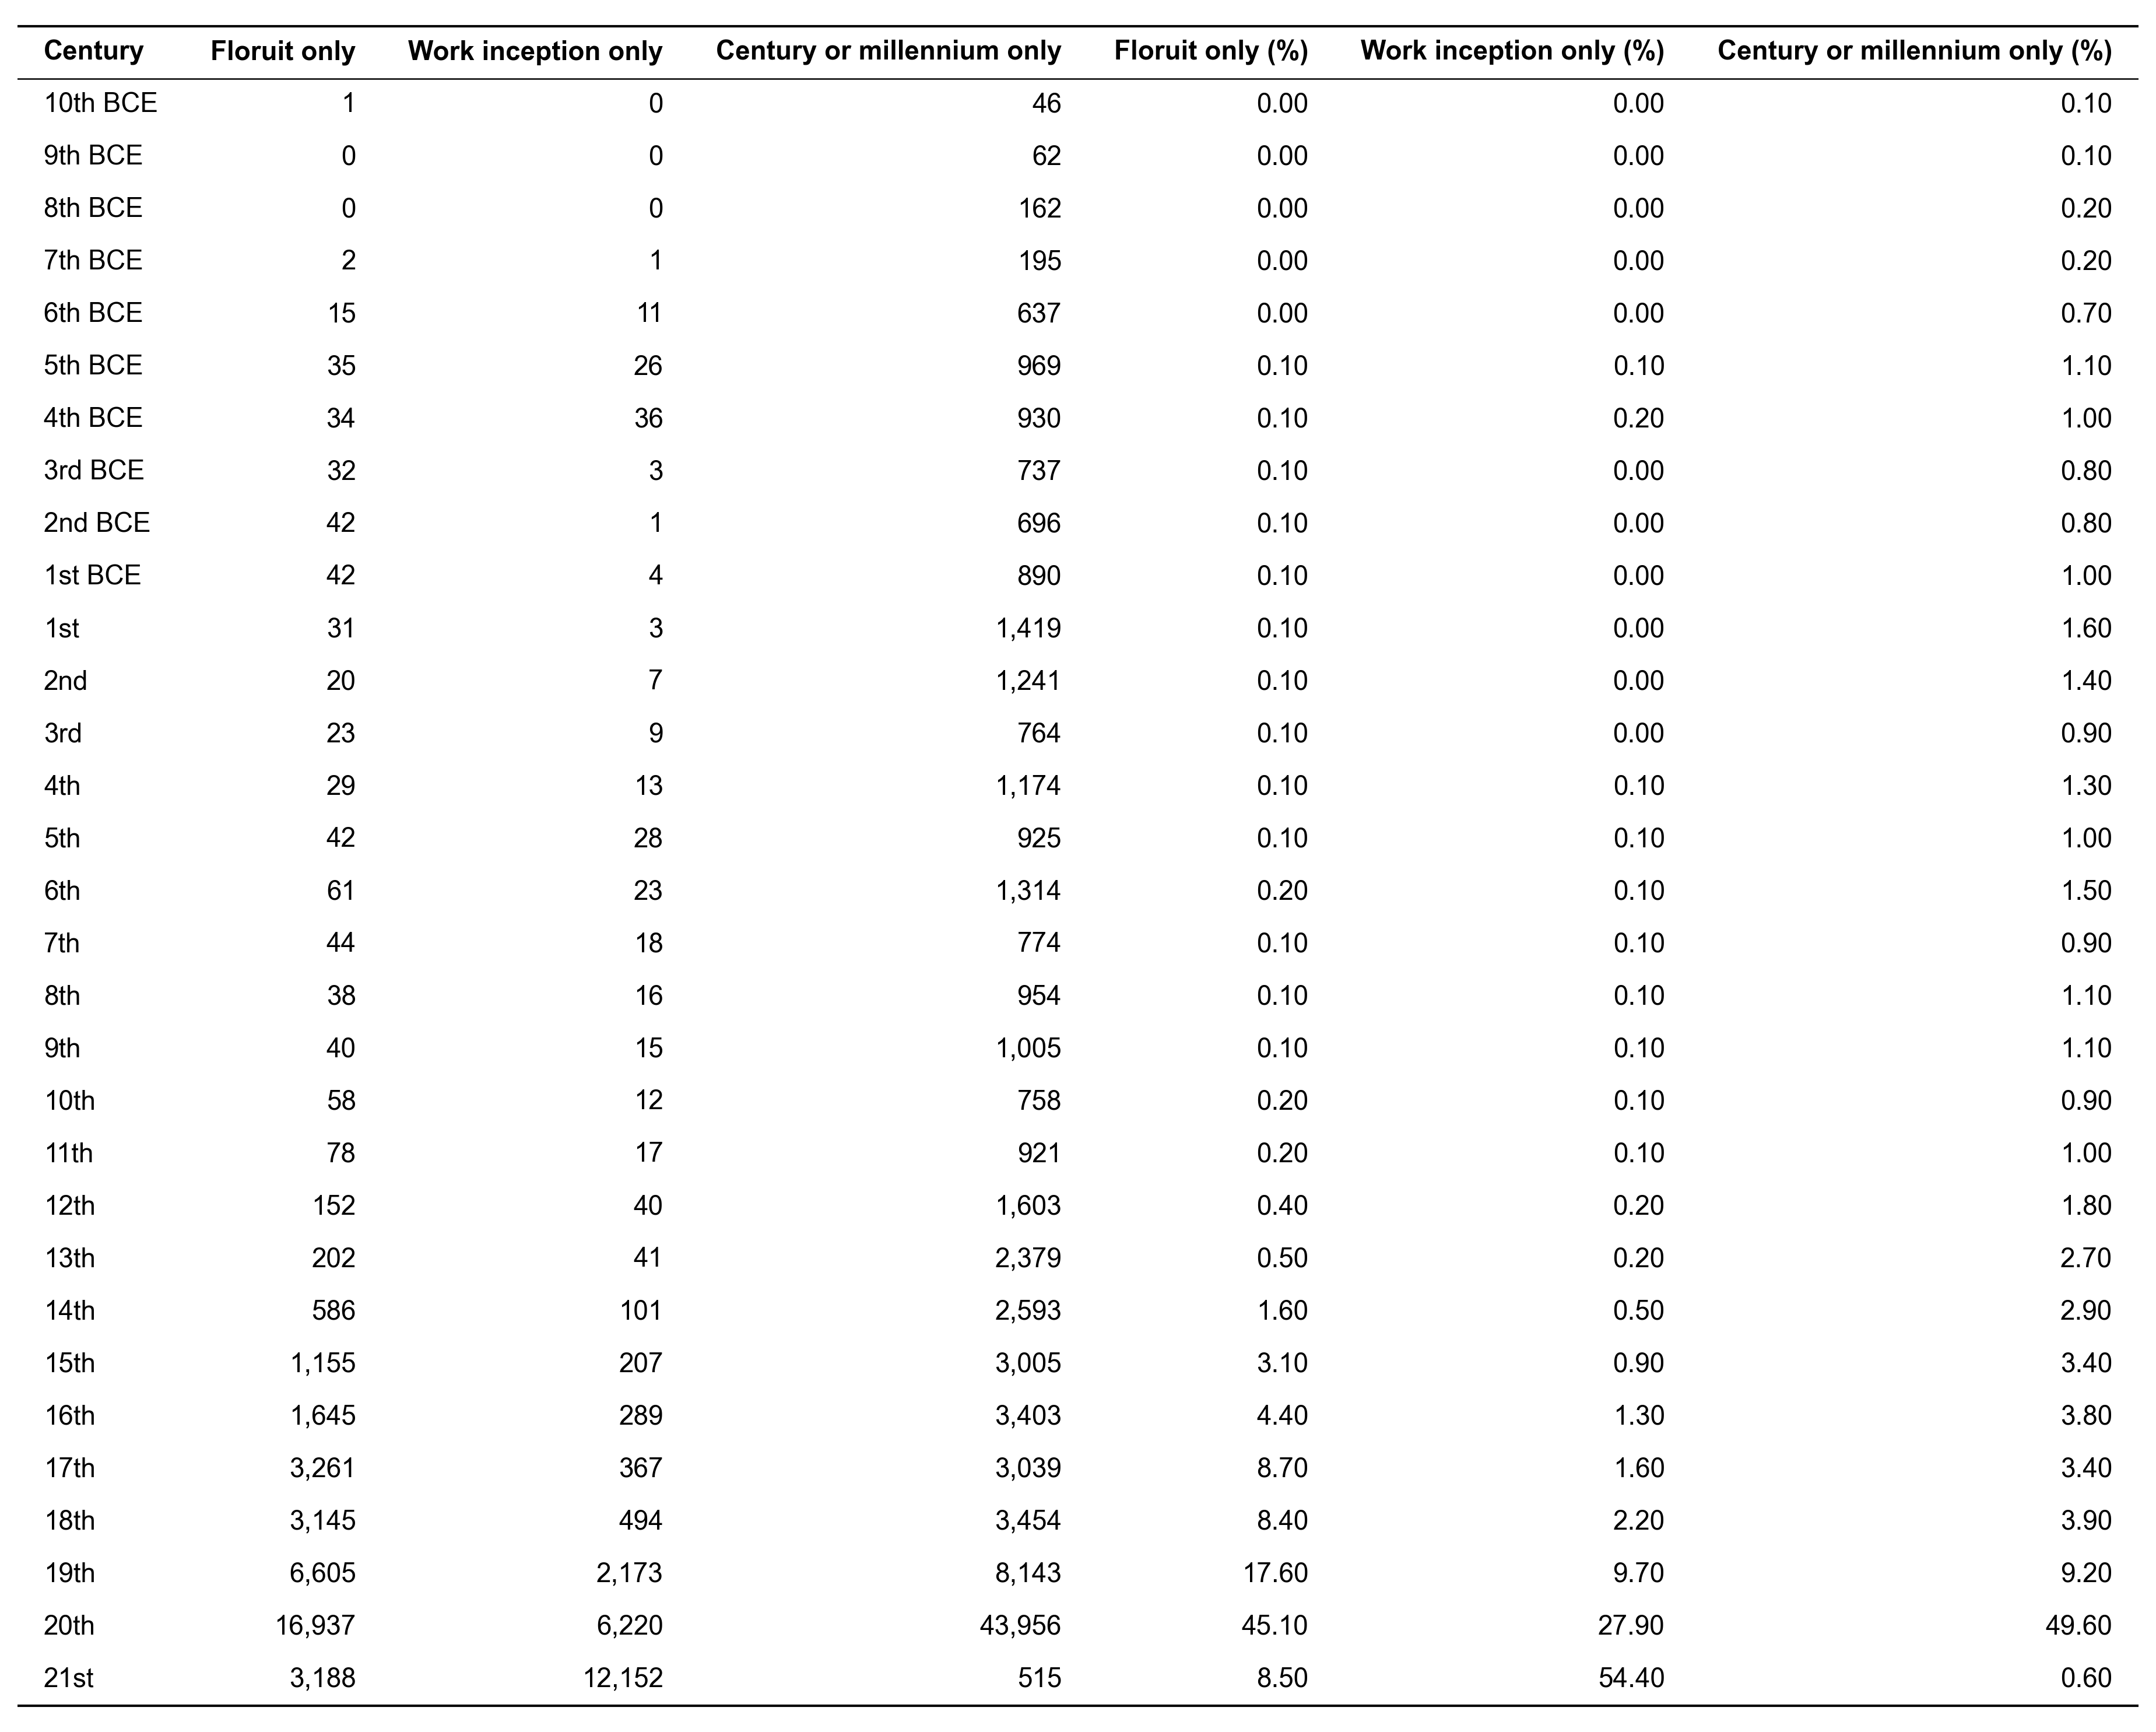

In [9]:
isolated = isolated.with_columns((pl.col('year') // 100 * 100).alias('century'))
by_century = (
    isolated.filter(pl.col('century').is_between(FIRST_CENTURY, LAST_CENTURY))
    .pivot(on='group', index='century', values='qid', aggregate_function='len')
    .fill_null(0)
    .sort('century')
)
outside = isolated.filter(~pl.col('century').is_between(FIRST_CENTURY, LAST_CENTURY)).height
print(f'{outside:,} individuals outside {FIRST_CENTURY}–{LAST_CENTURY} left out of the table')

show_table(by_century.select(
    pl.col('century').map_elements(century_label, return_dtype=pl.String).alias('Century'),
    *[pl.col(group).alias(f'{group}') for group in GROUPS],
    *[(100 * pl.col(group) / pl.col(group).sum()).round(1).alias(f'{group} (%)') for group in GROUPS],
))

## Figure: individuals by century

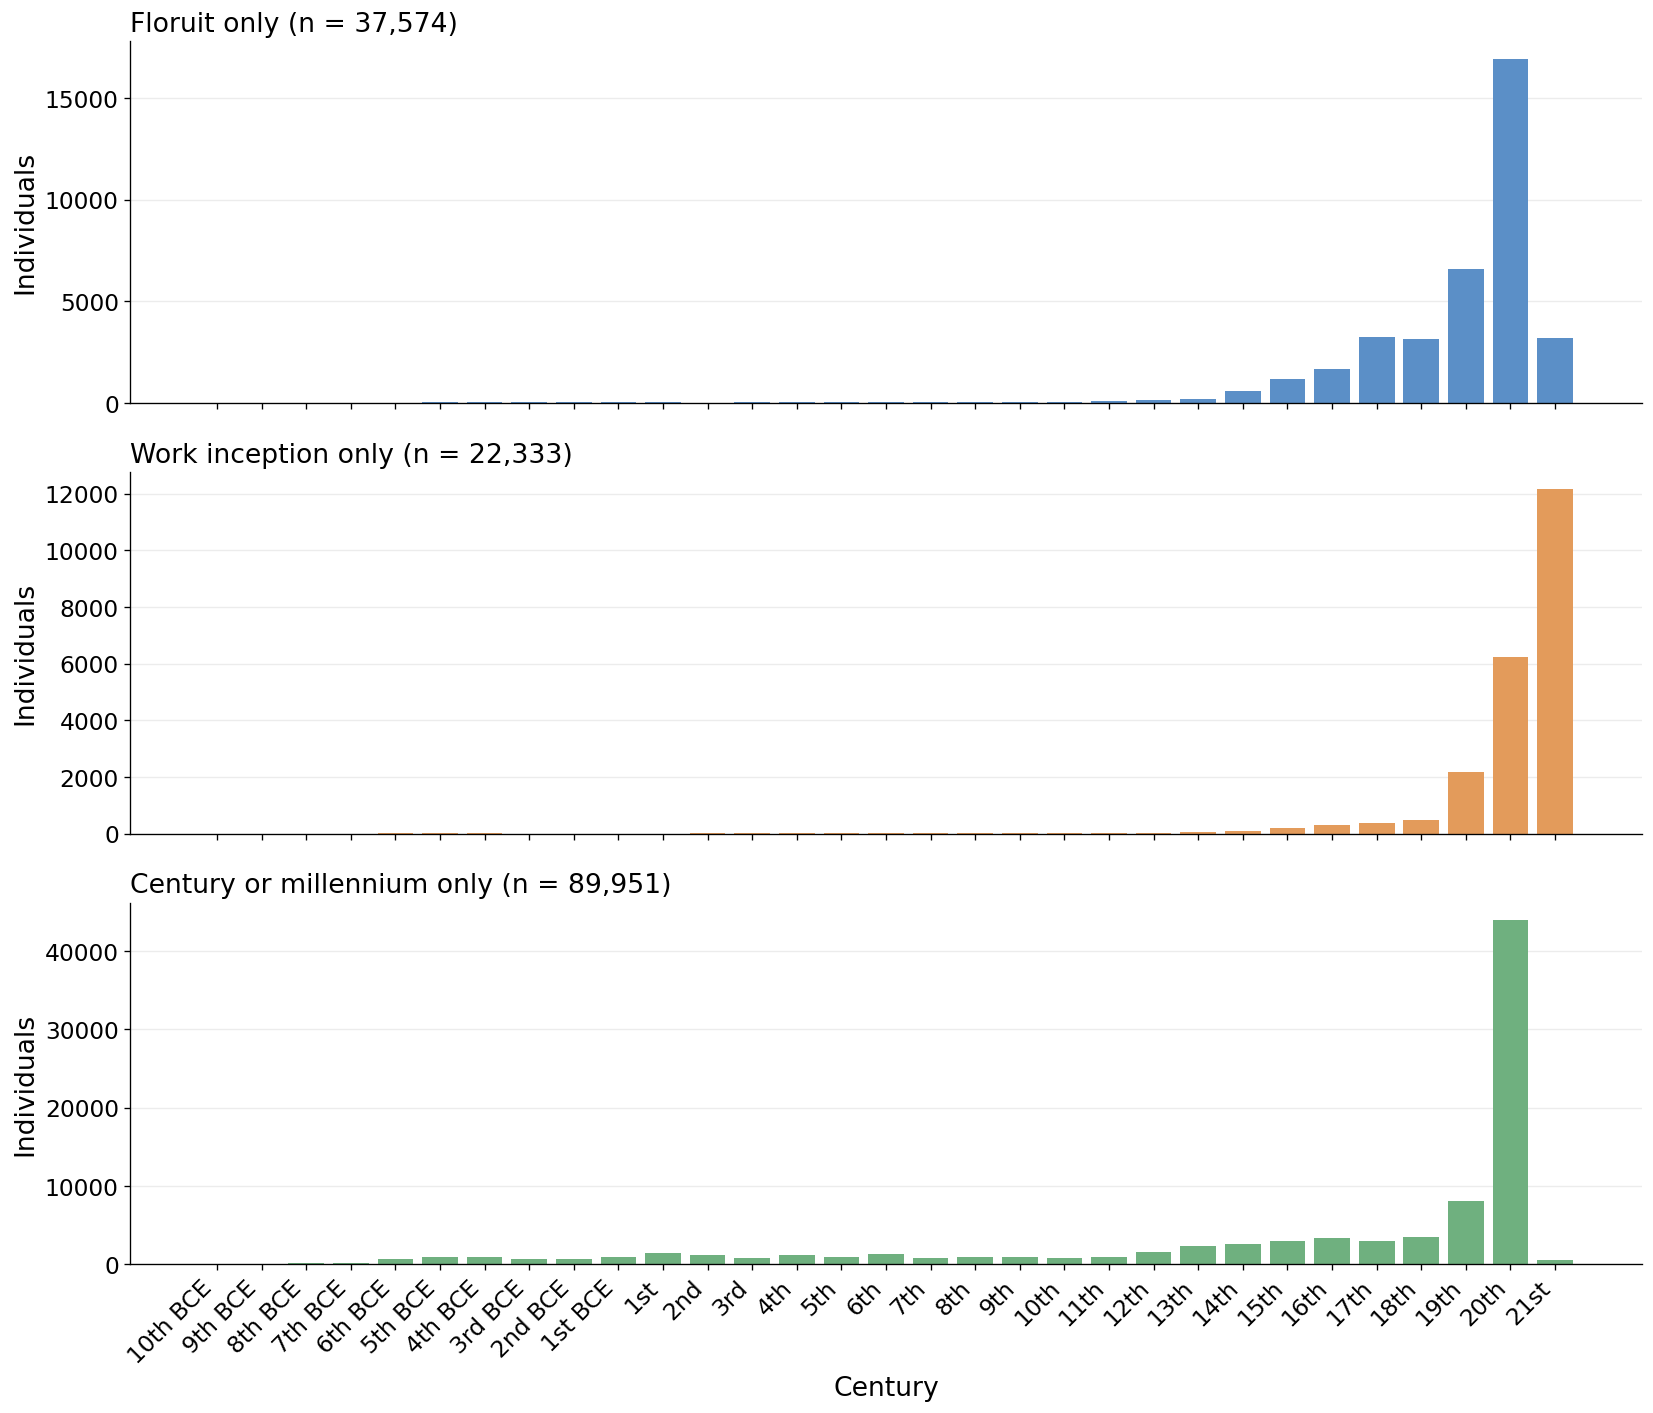

In [10]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)
for ax, (group, color) in zip(axes, GROUPS.items()):
    ax.bar(by_century['century'] + 50, by_century[group], width=80, color=color)
    ax.set_title(f"{group} (n = {isolated.filter(pl.col('group') == group).height:,})", loc='left')
    ax.set_ylabel('Individuals')
    ax.grid(axis='y')
ticks = list(range(FIRST_CENTURY, LAST_CENTURY + 1, 100))
axes[-1].set_xticks([tick + 50 for tick in ticks])
axes[-1].set_xticklabels([century_label(tick) for tick in ticks], rotation=45, ha='right')
axes[-1].set_xlabel('Century')
plt.tight_layout()
plt.show()